In [2]:
import os

print("Lokasi saat ini:", os.getcwd())
print("Isi folder:", os.listdir())

Lokasi saat ini: /content
Isi folder: ['.config', 'sample_data']


In [6]:
import os

print(os.listdir('/content'))

['.config', 'dataset_simuteh.zip', 'sample_data']


In [7]:
import zipfile
import os

with zipfile.ZipFile('/content/dataset_simuteh.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')

print("Berhasil diekstrak!")
print(os.listdir('/content'))

Berhasil diekstrak!
['.config', 'data', 'dataset_simuteh.zip', 'sample_data']


In [11]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

def baca(path):
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Gambar tidak ditemukan: {path}")
    return img

def statistik(gray):
    return {
        "rerata": np.mean(gray),
        "simpangan_baku": np.std(gray),
        "min": np.min(gray),
        "maks": np.max(gray)
    }

def kontras_bercak(gray, md, mb):
    daun = gray[md > 0]
    bercak = gray[mb > 0]

    return abs(np.mean(daun) - np.mean(bercak))

In [12]:
img = baca('/content/data/sintetis/citra/teh_041.png')
print("Ukuran citra:", img.shape)

Ukuran citra: (480, 640, 3)


In [10]:
import os

for item in os.listdir('/content'):
    lokasi = os.path.join('/content', item)
    print("\n", item)

    if os.path.isdir(lokasi):
        print(os.listdir(lokasi))


 .config
['configurations', '.last_survey_prompt.yaml', '.last_update_check.json', 'gce', 'active_config', 'hidden_gcloud_config_universe_descriptor_data_cache_configs.db', '.last_opt_in_prompt.yaml', 'logs', 'default_configs.db', 'config_sentinel']

 data
['sintetis']

 dataset_simuteh.zip

 sample_data
['README.md', 'anscombe.json', 'california_housing_train.csv', 'mnist_train_small.csv', 'mnist_test.csv', 'california_housing_test.csv']


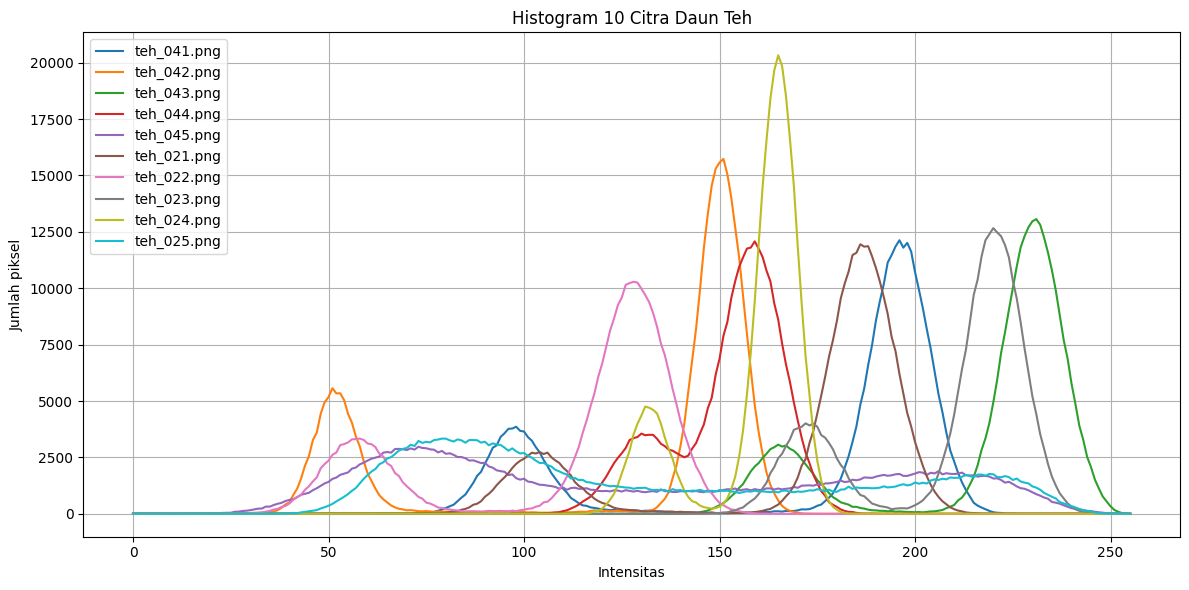

,Citra,Rerata,Simp. baku,Min-maks,% gelap,% terang
0,teh_041.png,172.06,42.61,67-233,0.00,21.49
1,teh_042.png,124.54,43.20,16-174,8.58,0.00
2,teh_043.png,217.56,26.55,134-255,0.00,80.03
3,teh_044.png,152.13,14.08,98-192,0.00,0.00
4,teh_045.png,129.67,59.50,8-255,4.39,17.63
5,teh_021.png,170.52,33.54,69-224,0.00,3.69
6,teh_022.png,110.67,31.54,14-167,4.49,0.00
7,teh_023.png,208.59,21.75,141-252,0.00,74.69
8,teh_024.png,158.47,13.91,110-186,0.00,0.00
9,teh_025.png,130.48,55.48,30-252,0.39,17.87


In [13]:
daftar_citra = [
    "teh_041.png",
    "teh_042.png",
    "teh_043.png",
    "teh_044.png",
    "teh_045.png",
    "teh_021.png",
    "teh_022.png",
    "teh_023.png",
    "teh_024.png",
    "teh_025.png"
]

hasil_statistik = []

plt.figure(figsize=(12, 6))

for nama in daftar_citra:
    img = baca(f"/content/data/sintetis/citra/{nama}")
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    stat = statistik(gray)

    hasil_statistik.append({
        "Citra": nama,
        "Rerata": stat["rerata"],
        "Simp. baku": stat["simpangan_baku"],
        "Min-maks": f'{stat["min"]}-{stat["maks"]}',
        "% gelap": np.mean(gray < 50) * 100,
        "% terang": np.mean(gray > 200) * 100
    })

    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)

plt.xlabel("Intensitas")
plt.ylabel("Jumlah piksel")
plt.title("Histogram 10 Citra Daun Teh")
plt.legend()
plt.grid()
plt.tight_layout()

os.makedirs("/content/hasil", exist_ok=True)
plt.savefig("/content/hasil/b3_histogram_10citra.png")
plt.show()

df_statistik = pd.DataFrame(hasil_statistik)
display(df_statistik.round(2))

df_statistik.to_csv(
    "/content/hasil/b3_statistik_10citra.csv",
    index=False
)

In [14]:
print(df_statistik.to_string(index=False))

      Citra     Rerata  Simp. baku Min-maks  % gelap  % terang
teh_041.png 172.062900   42.610979   67-233 0.000000 21.492513
teh_042.png 124.540853   43.198603   16-174 8.577474  0.000000
teh_043.png 217.555003   26.545696  134-255 0.000000 80.031901
teh_044.png 152.126488   14.076096   98-192 0.000000  0.000000
teh_045.png 129.671442   59.495986    8-255 4.394206 17.631836
teh_021.png 170.523005   33.543526   69-224 0.000000  3.693685
teh_022.png 110.673617   31.536457   14-167 4.487956  0.000000
teh_023.png 208.589495   21.749804  141-252 0.000000 74.694336
teh_024.png 158.474919   13.912123  110-186 0.000000  0.000000
teh_025.png 130.476989   55.475798   30-252 0.392253 17.866862


In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Membaca citra dan mask
nama = "teh_045.png"

img = baca(f"/content/data/sintetis/citra/{nama}")
md = cv2.imread(
    f"/content/data/sintetis/mask_daun/{nama}", 0
)
mb = cv2.imread(
    f"/content/data/sintetis/mask_bercak/{nama}", 0
)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Fungsi koreksi gamma
def gamma_lut(g):
    lut = np.array([
        255 * (i / 255) ** g for i in range(256)
    ])
    return lut.clip(0, 255).astype(np.uint8)

# Peregangan kontras
rmin, rmax = np.percentile(gray, (2, 98))

# Menerapkan berbagai metode perbaikan
hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(
        gray, alpha=1.5, beta=-40
    ),
    "regang": np.clip(
        (gray - rmin) / (rmax - rmin) * 255,
        0, 255
    ).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    ).apply(gray)
}

# Menghitung KB dan simpangan baku
data_hasil = []

for nm, c in hasil.items():
    kb = kontras_bercak(c, md, mb)
    sigma = c.std()

    print(
        f"{nm:10s} KB={kb:.2f} "
        f"sigma={sigma:.2f}"
    )

    data_hasil.append({
        "Metode": nm,
        "KB": kb,
        "Simpangan baku": sigma
    })

df_perbaikan = pd.DataFrame(data_hasil)

display(df_perbaikan.round(2))

df_perbaikan.to_csv(
    "/content/hasil/b3_hasil_perbaikan.csv",
    index=False
)

asli       KB=26.81 sigma=59.50
negatif    KB=26.81 sigma=59.50
cerah+50   KB=26.81 sigma=56.26
kontras    KB=40.24 sigma=81.46
regang     KB=36.09 sigma=80.16
gamma0.5   KB=22.52 sigma=42.76
gamma1.8   KB=21.82 sigma=64.95
ekualisasi KB=40.18 sigma=73.52
CLAHE      KB=42.57 sigma=48.18


,Metode,KB,Simpangan baku
0,asli,26.81,59.50
1,negatif,26.81,59.50
2,cerah+50,26.81,56.26
3,kontras,40.24,81.46
4,regang,36.09,80.16
5,gamma0.5,22.52,42.76
6,gamma1.8,21.82,64.95
7,ekualisasi,40.18,73.52
8,CLAHE,42.57,48.18


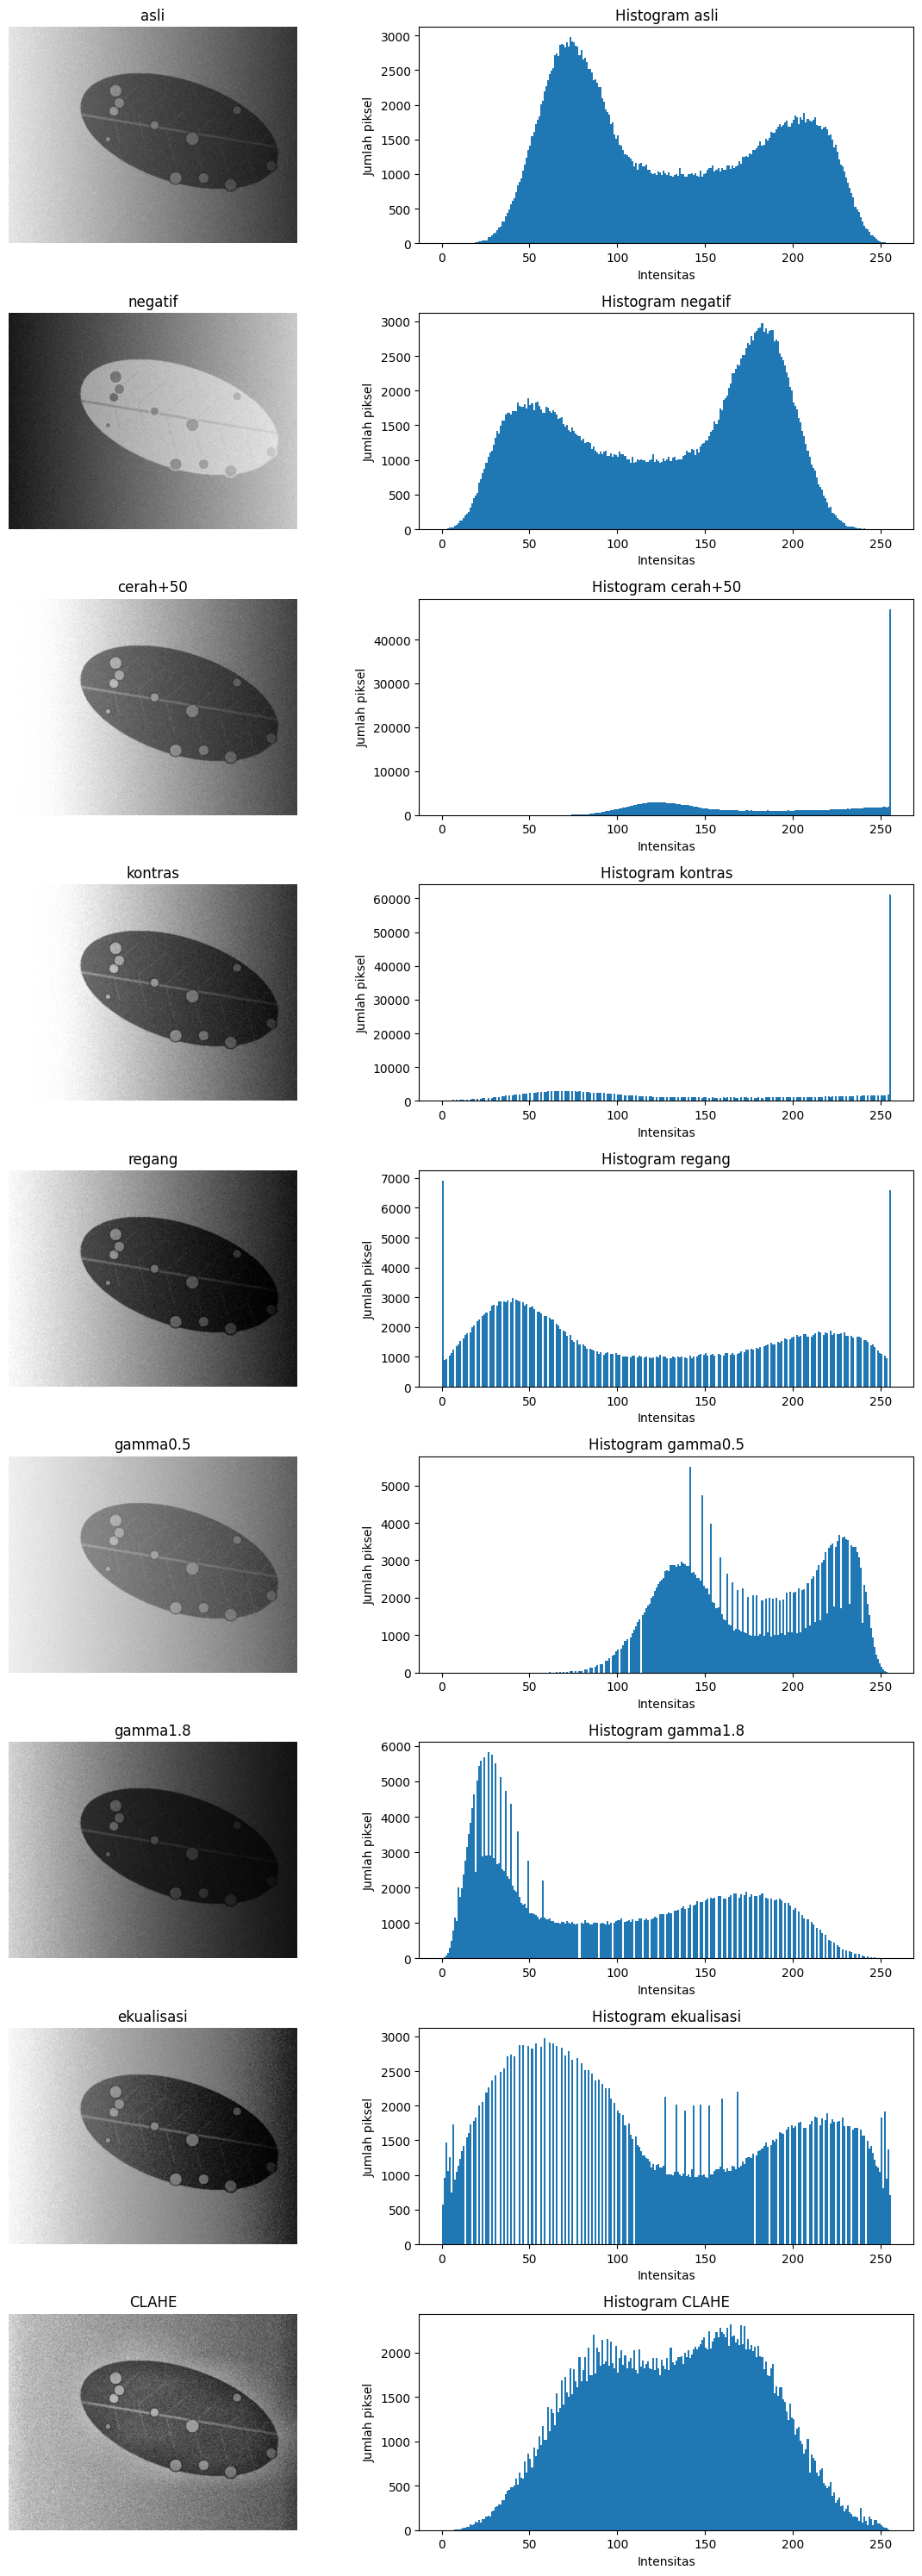

In [16]:
fig, axes = plt.subplots(
    len(hasil), 2,
    figsize=(12, 30)
)

for i, (nm, c) in enumerate(hasil.items()):

    axes[i, 0].imshow(c, cmap="gray")
    axes[i, 0].set_title(nm)
    axes[i, 0].axis("off")

    axes[i, 1].hist(
        c.ravel(),
        bins=256,
        range=(0, 256)
    )
    axes[i, 1].set_title(
        f"Histogram {nm}"
    )
    axes[i, 1].set_xlabel("Intensitas")
    axes[i, 1].set_ylabel("Jumlah piksel")

plt.tight_layout()

plt.savefig(
    "/content/hasil/b3_perbandingan_perbaikan.png"
)

plt.show()

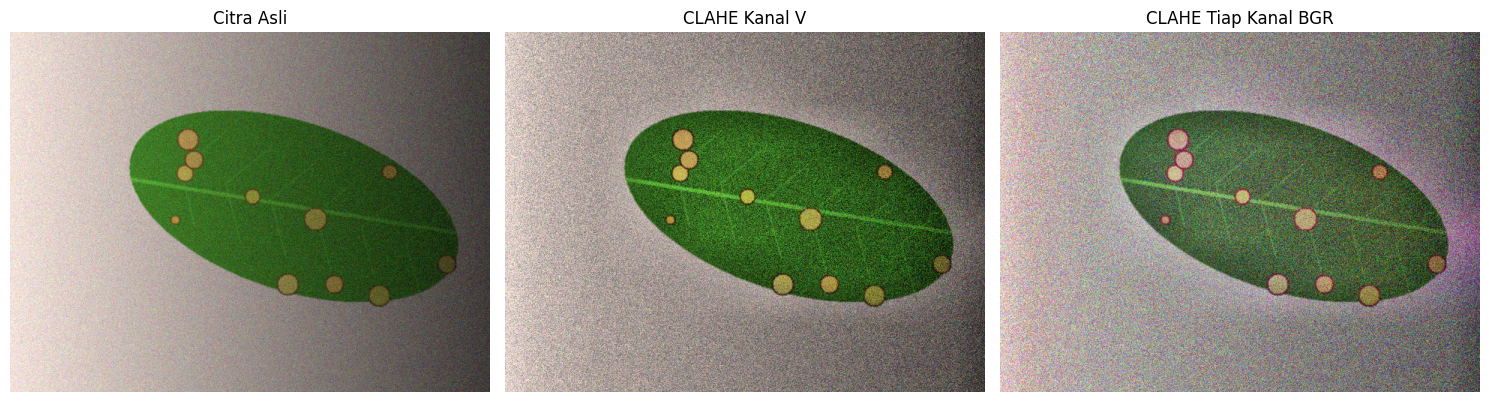

In [18]:
# Menampilkan perbandingan CLAHE
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

daftar_gambar = [img, via_v, via_bgr]
judul = [
    "Citra Asli",
    "CLAHE Kanal V",
    "CLAHE Tiap Kanal BGR"
]

for ax, gambar, nama in zip(axes, daftar_gambar, judul):
    ax.imshow(cv2.cvtColor(gambar, cv2.COLOR_BGR2RGB))
    ax.set_title(nama)
    ax.axis("off")

plt.tight_layout()
plt.savefig("/content/hasil/b3_perbandingan_CLAHE_warna.png")
plt.show()

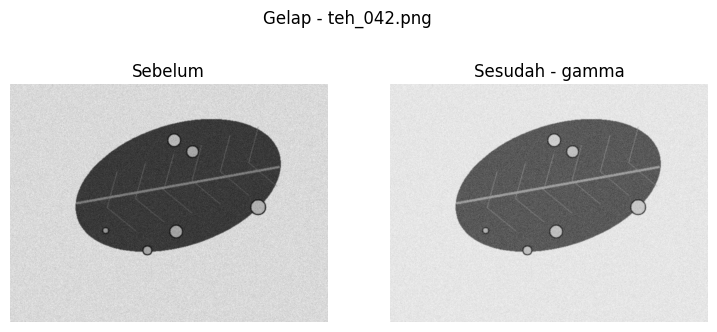

teh_042.png Selesai diperbaiki


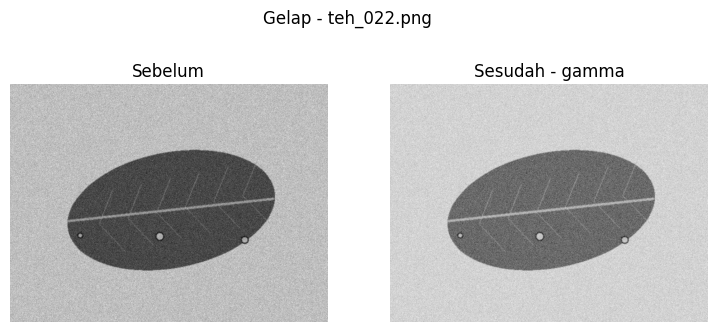

teh_022.png Selesai diperbaiki


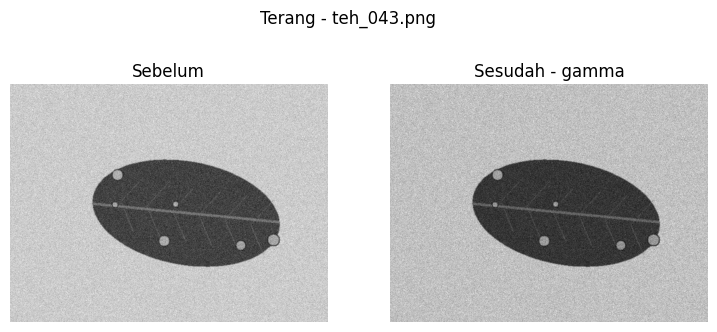

teh_043.png Selesai diperbaiki


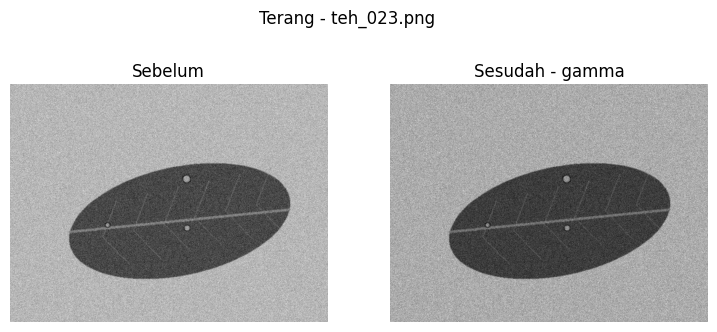

teh_023.png Selesai diperbaiki


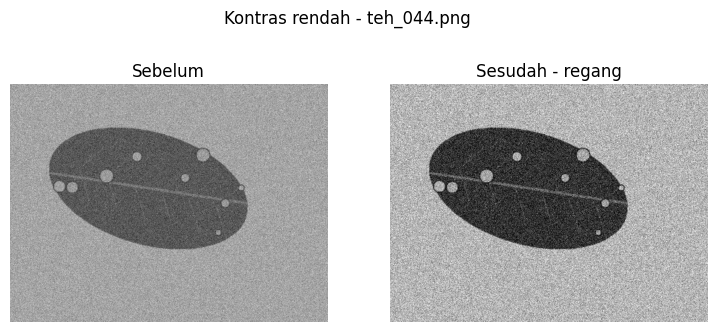

teh_044.png Selesai diperbaiki


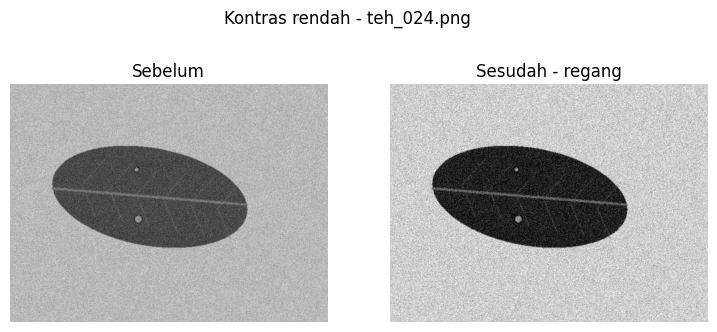

teh_024.png Selesai diperbaiki


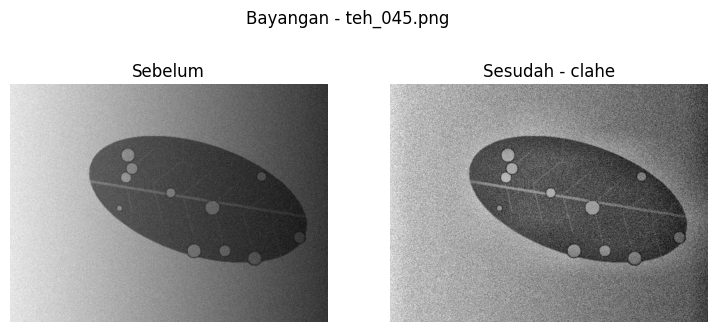

teh_045.png Selesai diperbaiki


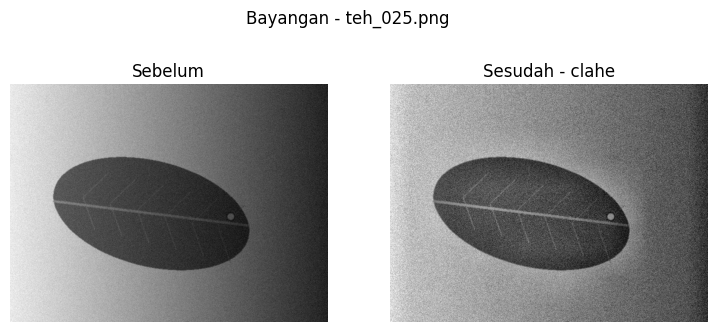

teh_025.png Selesai diperbaiki


In [19]:
pasangan = [
    ("Gelap", "teh_042.png", "teh_022.png", "gamma"),
    ("Terang", "teh_043.png", "teh_023.png", "gamma"),
    ("Kontras rendah", "teh_044.png", "teh_024.png", "regang"),
    ("Bayangan", "teh_045.png", "teh_025.png", "clahe")
]

def perbaiki(gray, metode):
    if metode == "gamma":
        g = 0.5 if np.mean(gray) < 140 else 1.8
        return cv2.LUT(gray, gamma_lut(g))

    elif metode == "regang":
        rmin, rmax = np.percentile(gray, (2, 98))
        return np.clip(
            (gray-rmin)/(rmax-rmin)*255, 0, 255
        ).astype(np.uint8)

    elif metode == "clahe":
        return cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8,8)
        ).apply(gray)

for kondisi, berat, ringan, metode in pasangan:
    for nama in [berat, ringan]:
        img = baca(f"/content/data/sintetis/citra/{nama}")
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        hasil_baru = perbaiki(gray, metode)

        plt.figure(figsize=(9,4))

        plt.subplot(1,2,1)
        plt.imshow(gray, cmap="gray")
        plt.title("Sebelum")
        plt.axis("off")

        plt.subplot(1,2,2)
        plt.imshow(hasil_baru, cmap="gray")
        plt.title("Sesudah - " + metode)
        plt.axis("off")

        plt.suptitle(kondisi + " - " + nama)
        plt.show()

        print(nama, "Selesai diperbaiki")

In [20]:
hasil_b3_5 = []

for kondisi, berat, ringan, metode in pasangan:
    for nama in [berat, ringan]:

        img = baca(f"/content/data/sintetis/citra/{nama}")
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        md = cv2.imread(
            f"/content/data/sintetis/mask_daun/{nama}", 0
        )
        mb = cv2.imread(
            f"/content/data/sintetis/mask_bercak/{nama}", 0
        )

        hasil_baru = perbaiki(gray, metode)

        hasil_b3_5.append({
            "Kondisi": kondisi,
            "Citra": nama,
            "Metode": metode,
            "KB sebelum": kontras_bercak(gray, md, mb),
            "KB sesudah": kontras_bercak(hasil_baru, md, mb)
        })

df_b3_5 = pd.DataFrame(hasil_b3_5)

display(df_b3_5.round(2))

df_b3_5.to_csv(
    "/content/hasil/b3_5_perbaikan_empat_kondisi.csv",
    index=False
)

,Kondisi,Citra,Metode,KB sebelum,KB sesudah
0,Gelap,teh_042.png,gamma,39.87,33.89
1,Gelap,teh_022.png,gamma,18.47,14.03
2,Terang,teh_043.png,gamma,29.05,41.26
3,Terang,teh_023.png,gamma,13.02,18.99
4,Kontras rendah,teh_044.png,regang,14.98,70.14
5,Kontras rendah,teh_024.png,regang,8.24,45.60
6,Bayangan,teh_045.png,clahe,26.81,42.57
7,Bayangan,teh_025.png,clahe,5.29,18.87
